In [275]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

pd.set_option("display.max_colwidth", 800)
pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

DATA_DIR = Path("data")

TRAIN_PATH = DATA_DIR / "train.csv"
VALIDATION_PATH = DATA_DIR / "validation.csv"
TEST_PATH = DATA_DIR / "test.csv"
MAPPING_PATH = DATA_DIR / "label_mapping.csv"
SUBMISSION_PATH = DATA_DIR / "sample_submission.csv"

In [219]:
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VALIDATION_PATH)
test_df = pd.read_csv(TEST_PATH)
label_mapping_df = pd.read_csv(MAPPING_PATH)
sample_submission_df = pd.read_csv(SUBMISSION_PATH)
train_val_df = pd.concat([train_df, val_df])
train_df = train_df.copy()
val_raw = val_df.copy()
test_raw = test_df.copy()


In [220]:
datasets = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df,
    "Label Mapping": label_mapping_df,
    "Sample Submission": sample_submission_df
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

Train: 58,135 rows, 3 columns
Validation: 7,267 rows, 3 columns
Test: 7,267 rows, 2 columns
Label Mapping: 10 rows, 2 columns
Sample Submission: 7,267 rows, 2 columns


In [221]:
for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nInfo:")
    df.info()



Train

Columns:
['id', 'question', 'category']

Data types:
id          int64
question      str
category      str
dtype: object

First 5 rows:


,id,question,category
0,5034,العمر ٤٢ سنة مريض ضغط باخد بيزوكارد10 اشعر بإرهاق عام دائما فذهبت لعمل تحليل سكر تراكمي فهل انا اعاني من السكري من فضلك دكتور وما نصائحك في الحياة اليومية والغذاء والعلاج,أمراض الغدد الصماء
1,44388,اعاني من فقر الدم . هل يمكنني ان القح نفسي بحقنة مضادة لفيروس كورونا ؟,الطب العام
2,37246,منذ حوالي خمسة أشهر، لاحظت نزول دم مع البراز لمدة أسبوع تقريبًا، ولم يكن مصحوبًا بأي ألم. أجريت منظارًا للقولون، وكانت النتيجة طبيعية. بالإضافة إلى ذلك، تظهر لدي أحيانًا نقاط حمراء صغيرة تحت الجلد، وأعاني من عدم انتظام الدورة الشهرية، حيث تأتي مرتين في بعض الأشهر. ما هي الأسباب المحتملة لهذه الأعراض المتنوعة، وما هي الفحوصات التي تنصحون بإجرائها؟,الطب العام
3,3785,انا فتاه غير متزوجة عمري 34 سنه وزني 75 سنه وطولي 160 اعاني من مشكلة الحديد . حيث دائما اراجع دكتور الغدة ودائما وفي كل فحص (خمس اشهر) يطلب مني دائما فحص الحديد وفي كل مره يكون سلبي ويكتب لي حبوب . وفي كل يزيد الجرعة اخر مره الحديد وصل الى ferritin - 19.3 ug/L بالرغم من انني شهر من علاجي للحديد وباقي شهر حيث اعطاني الدكتور فيروفيتا ما سبب نقص الحديد عندي رغم ان اكلي عادي واحب الكبدة لكن لا ا...,أمراض الدم
4,21193,تاخرت الدورة 14 يوم وعملت اختبار دم اليوم طلع حمل ضعيف وفي ميعاد الدورة نزل افرازات بنية هل هذا حمل,أمراض نسائية



Info:
<class 'pandas.DataFrame'>
RangeIndex: 58135 entries, 0 to 58134
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        58135 non-null  int64
 1   question  58135 non-null  str  
 2   category  58135 non-null  str  
dtypes: int64(1), str(2)
memory usage: 1.3 MB

Validation

Columns:
['id', 'question', 'category']

Data types:
id          int64
question      str
category      str
dtype: object

First 5 rows:


,id,question,category
0,18658,لدي من كمية افرازات قليلة خلال فتره التبويض فهل هذا يؤثر على جودة التبويض وحدوث الحمل؟,أمراض نسائية
1,4531,أنا لدي زوائد جلدية قريبة من منطقة الإبط و عدم إنتظام الدورة الشهرية و زيادة وزن منطقة البطن و كثرة الشعر الزائد و فراغ الشعر من الأمام.على ماذا تدل هذه الأعراض,أمراض الغدد الصماء
2,55306,هل العسل مع ماء دافئ مضر لطفل عمره سته شهور,امراض الاطفال
3,61346,انا نظري ضغيف اذا ظغطت على المنطقه تحت الحواجب اشوف زين لماذا,امراض العيون
4,11065,السلام عليكم انا فتاة كنت مريضة بالتهاب غدد النكافية لمدة 12 يوم والان اعاني من جفاف الفم و تقرحات الفم وصعوبة البلع لقلة اللعاب هل كل هده اعراض سببها التهاب غدد النكافية? شكر,أمراض الغدد الصماء



Info:
<class 'pandas.DataFrame'>
RangeIndex: 7267 entries, 0 to 7266
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        7267 non-null   int64
 1   question  7267 non-null   str  
 2   category  7267 non-null   str  
dtypes: int64(1), str(2)
memory usage: 170.4 KB

Test

Columns:
['id', 'question']

Data types:
id          int64
question      str
dtype: object

First 5 rows:


,id,question
0,24452,انا فتاه عمري 21سنه قبل اربع شهور كنت بوضع عصبيه بشده فارتفع عندي الضغط205/130 وصار عندي نزيف انف وفقدت الوعي وتكرر ارتفاعه لفتره والان اعاني منه بشكل دائم حتى في الراحه ما حل
1,10653,أعاني من زيادة الوزن السريعة وانا انتظم في الأكل والعلاج حبوب وانسولين ولاكن الريادة في الوزن مستمرة فما العمل ارجوالرد المقنع اريد وصفة طبية لنقصان الوزن ارجوكم ريحوني
2,16110,هل يمكن حدوث حمل مباشرةً بعد التوقف عن تناول دواء ديستونكس الخافض لارتفاع هرمون الحليب، أم يجب انتظار الدورة الشهرية التالية؟
3,40095,السلام عليكم خربشتني قطة صغيرة من الشارع ونزف منها الدم واعطوني لقاح ضد داء الكلب ولكن في العضلة الخلفية هل هو فعال او لا يجب في الكتف علما في الامس
4,47029,عندي طفلة رضيعة لم تتجاوز الشهر عندها يومين لم تتبرز وتجد صعوبة في ذلك وهي تبكي باستمرار هل من حل سريع بارك الله فيكم ضروري الرد السريع



Info:
<class 'pandas.DataFrame'>
RangeIndex: 7267 entries, 0 to 7266
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        7267 non-null   int64
 1   question  7267 non-null   str  
dtypes: int64(1), str(1)
memory usage: 113.7 KB

Label Mapping

Columns:
['category', 'label_id']

Data types:
category      str
label_id    int64
dtype: object

First 5 rows:


,category,label_id
0,أمراض العيون,0
1,الأمراض الجلدية,1
2,الطب العام,2
3,أمراض نسائية,3
4,أمراض الغدد الصماء,4



Info:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   category  10 non-null     str  
 1   label_id  10 non-null     int64
dtypes: int64(1), str(1)
memory usage: 292.0 bytes

Sample Submission

Columns:
['id', 'category']

Data types:
id            int64
category    float64
dtype: object

First 5 rows:


,id,category
0,24452,NaN
1,10653,NaN
2,16110,NaN
3,40095,NaN
4,47029,NaN



Info:
<class 'pandas.DataFrame'>
RangeIndex: 7267 entries, 0 to 7266
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        7267 non-null   int64  
 1   category  0 non-null      float64
dtypes: float64(1), int64(1)
memory usage: 113.7 KB


In [222]:
for name, df in datasets.items():
    print(f"\n{name}")

    missing = pd.DataFrame({
        "Missing Count": df.isna().sum(),
        "Missing Percentage": df.isna().mean() * 100
    })

    display(missing)


Train


,Missing Count,Missing Percentage
id,0,0.0
question,0,0.0
category,0,0.0



Validation


,Missing Count,Missing Percentage
id,0,0.0
question,0,0.0
category,0,0.0



Test


,Missing Count,Missing Percentage
id,0,0.0
question,0,0.0



Label Mapping


,Missing Count,Missing Percentage
category,0,0.0
label_id,0,0.0



Sample Submission


,Missing Count,Missing Percentage
id,0,0.0
category,7267,100.0


In [223]:
for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum():,} duplicate rows")

Train: 0 duplicate rows
Validation: 0 duplicate rows
Test: 0 duplicate rows
Label Mapping: 0 duplicate rows
Sample Submission: 0 duplicate rows


In [224]:
def check_duplicates(train_df, val_df, test_df = None):
    for name, df in {
        "Train": train_df,
        "Validation": val_df,
        "Train-val": pd.concat([train_df,val_df]),
        "Test": test_df
    }.items():
        if df is None:
            continue
        print(
            f"{name}: "
            f"{df[['question']].duplicated().sum():,} duplicate questions"
        )
        if 'category' in df.columns:
            
            print(
                f"With Category: "
                f"{df.drop(columns=['id']).duplicated().sum():,} duplicate questions"
            )
            
check_duplicates(train_df, val_df,test_df)

Train: 25 duplicate questions
With Category: 22 duplicate questions
Validation: 0 duplicate questions
With Category: 0 duplicate questions
Train-val: 31 duplicate questions
With Category: 25 duplicate questions
Test: 0 duplicate questions


In [225]:
print(train_df['id'].nunique() == train_df.shape[0],
      val_df['id'].nunique() == val_df.shape[0],
      train_val_df['id'].nunique() == train_val_df.shape[0])

True True True


In [226]:
def check_duplicated_conflict_categories(train_df, val_df):
    full_df = pd.concat([train_df.assign(split='Train'), val_df.assign(split='Val')], ignore_index=True)

    conflicting_questions = (
        full_df.groupby('question')['category']
        .nunique()
        .loc[lambda x: x > 1]
        .index
    )

    conflicts_df = (
        full_df[full_df['question'].isin(conflicting_questions)]
        .sort_values(by=['question', 'split'])
    )

    print(conflicts_df.shape)
    display(conflicts_df[['split', 'id', 'question', 'category']])
    
check_duplicated_conflict_categories(train_df, val_df)

(12, 4)


,split,id,question,category
13498,Train,41166,السلام عليكم ورحمة الله\r\nعملت فحص للسكر صائم لاكثر من شهرين ونص وكلها لاتزيد على 90 وبعد الاكل بساعتين 125-145 وبعد الاكل بثلاث ساعات 115-130 ولكن السكر التراكمي قبل شهرين 6.4 والان 7.2 هل انا مريض سكر او لا,الطب العام
23360,Train,5537,السلام عليكم ورحمة الله\r\nعملت فحص للسكر صائم لاكثر من شهرين ونص وكلها لاتزيد على 90 وبعد الاكل بساعتين 125-145 وبعد الاكل بثلاث ساعات 115-130 ولكن السكر التراكمي قبل شهرين 6.4 والان 7.2 هل انا مريض سكر او لا,أمراض الغدد الصماء
9587,Train,41445,السلام عليكم ورحمة الله وبركاته \r\nممكن الرد على سؤالي و هو هل نسبة الهيموجلوبين ١٠.٨ يعتبر نسبة طبيعية لمرأة عمرها ٢١ سنة,الطب العام
59482,Val,2373,السلام عليكم ورحمة الله وبركاته \r\nممكن الرد على سؤالي و هو هل نسبة الهيموجلوبين ١٠.٨ يعتبر نسبة طبيعية لمرأة عمرها ٢١ سنة,امراض الدم
49476,Train,41568,انا عمري ١٧ سنه وطولي ١٦٨ سنتيمتر وانا اقصر من اخوتي بقد من ٥ الي ٧ سنتيمتر وذهبت لطبيب غدد صماء واخبرني ان مادام حدث بلوغ فلا يمكن اعطاء هرمون النمو و هذا الموضوع مؤثر بالنسبة لي ولا اعرف ان كنت اعاني من مشكلة تؤثر علي طولي ام لا وهل من الممكن ان اطول وجزاكم الله خيرا,الطب العام
58999,Val,5849,انا عمري ١٧ سنه وطولي ١٦٨ سنتيمتر وانا اقصر من اخوتي بقد من ٥ الي ٧ سنتيمتر وذهبت لطبيب غدد صماء واخبرني ان مادام حدث بلوغ فلا يمكن اعطاء هرمون النمو و هذا الموضوع مؤثر بالنسبة لي ولا اعرف ان كنت اعاني من مشكلة تؤثر علي طولي ام لا وهل من الممكن ان اطول وجزاكم الله خيرا,أمراض الغدد الصماء
37115,Train,41344,انا عملت تحليل انيميا وطلعت نسبه mchc 30 النسبه كدا مظبوطه ولا محتاج علاج لو محتاج علاج ايه العلاج المطلوب,الطب العام
42719,Train,2362,انا عملت تحليل انيميا وطلعت نسبه mchc 30 النسبه كدا مظبوطه ولا محتاج علاج لو محتاج علاج ايه العلاج المطلوب,امراض الدم
17242,Train,5633,انا عندي ارتفاع في الضغط استخدم دواء amlocard ولكن عند قياسه ارى ان هناك اختلف كبير في القرات تكون القراى الاولة 180/106 وتكون الاخيرة 150/83 هل هاذا طبيعي ام ماذ,أمراض الغدد الصماء
21053,Train,22043,انا عندي ارتفاع في الضغط استخدم دواء amlocard ولكن عند قياسه ارى ان هناك اختلف كبير في القرات تكون القراى الاولة 180/106 وتكون الاخيرة 150/83 هل هاذا طبيعي ام ماذ,ارتفاع ضغط الدم


In [227]:
def check_empty(train_df, val_df, test_df = None):
    for name, df in {
        "Train": train_df,
        "Validation": val_df,
        "Test": test_df
    }.items():
        if df is None: continue 
        empty_questions = (
            df["question"]
            .fillna("")
            .str.strip()
            .eq("")
        )

        print(f"{name}: {empty_questions.sum()} empty questions")
check_empty(train_df, val_df, test_df)

Train: 0 empty questions
Validation: 0 empty questions
Test: 0 empty questions


In [228]:
def clean_duplicates(train_df, val_df):
    # 1. Identify questions with conflicting categories across Train + Val (6 questions)
    combined = pd.concat([train_df, val_df], ignore_index=True)
    conflicting_questions = (
        combined.groupby('question')['category']
        .nunique()
        .loc[lambda x: x > 1]
        .index
    )

    # 2. Drop all conflicting questions from BOTH splits
    train_clean = train_df[~train_df['question'].isin(conflicting_questions)].copy()
    val_clean = val_df[~val_df['question'].isin(conflicting_questions)].copy()

    # 3. Drop exact duplicates (same question + same category) within Train and within Val
    train_clean = train_clean.drop_duplicates(subset=['question'], keep='first').reset_index(drop=True)
    val_clean = val_clean.drop_duplicates(subset=['question'], keep='first').reset_index(drop=True)

    # 4. Drop any remaining Val questions that already exist in Train (prevents leakage)
    val_clean = val_clean[~val_clean['question'].isin(train_clean['question'])].reset_index(drop=True)
    print(f"Train duplicates left:     {train_clean['question'].duplicated().sum()}")
    print(f"Val duplicates left:       {val_clean['question'].duplicated().sum()}")
    print(f"Train-Val overlap left:    {val_clean['question'].isin(train_clean['question']).sum()}")
    return train_clean, val_clean 
train_clean, val_clean = clean_duplicates(train_df, val_df)
check_duplicated_conflict_categories(train_clean,val_clean)


Train duplicates left:     0
Val duplicates left:       0
Train-Val overlap left:    0
(0, 4)


,split,id,question,category


In [229]:
train_df = train_clean
val_df = val_clean

### Observations 1
- datatypes are correct
- no empty questions
- no duplicated rows (since each row have a unique id)
- we have 25 duplicated question in train set, 31 in train-val, 0 in other sets
- an issue in the train set that we have 3 questions duplicated with differnt categories, and in train val the number increases to 6. i removed them rather than keeping them since we have enough samples.

### Target Analysis

In [230]:
num_categories = train_df["category"].nunique()

print("Number of categories:", num_categories)
print("Labled Categories:", label_mapping_df.shape)

Number of categories: 14
Labled Categories: (10, 2)


In [231]:
category_counts = train_df["category"].value_counts()

display(category_counts.to_frame("Count"))
display(label_mapping_df['category'])

,Count
category,
امراض العيون,7982
الأمراض الجلدية,7968
الطب العام,7947
أمراض نسائية,7947
أمراض الغدد الصماء,7458
امراض الاطفال,5133
ارتفاع ضغط الدم,3998
أمراض الأطفال,2847
صحة الاسنان,2355


0            أمراض العيون
1         الأمراض الجلدية
2              الطب العام
3            أمراض نسائية
4      أمراض الغدد الصماء
5           أمراض الأطفال
6         ارتفاع ضغط الدم
7             صحة الأسنان
8              أمراض الدم
9    أمراض الجهاز التنفسي
Name: category, dtype: str

seems we need to clean the categories, then recheck for duplicated values again, hope that this changes nothing

In [232]:
train_df['category'] = train_df['category'].str.replace('أ', 'ا', regex=False)
val_df['category'] = val_df['category'].str.replace('أ', 'ا', regex=False)
train_val_df = pd.concat([train_df, val_df])
label_mapping_df['category'] = label_mapping_df['category'].str.replace('أ', 'ا', regex=False)

num_categories = train_df["category"].nunique()

print("Number of categories:", num_categories)
print("Labled Categories:", label_mapping_df.shape)

category_counts = train_df["category"].value_counts()

display(category_counts.to_frame("Count"))
display(label_mapping_df['category'])

Number of categories: 10
Labled Categories: (10, 2)


,Count
category,
امراض العيون,7982
امراض الاطفال,7980
الامراض الجلدية,7968
الطب العام,7947
امراض نسائية,7947
امراض الغدد الصماء,7458
ارتفاع ضغط الدم,3998
صحة الاسنان,3277
امراض الدم,1932


0            امراض العيون
1         الامراض الجلدية
2              الطب العام
3            امراض نسائية
4      امراض الغدد الصماء
5           امراض الاطفال
6         ارتفاع ضغط الدم
7             صحة الاسنان
8              امراض الدم
9    امراض الجهاز التنفسي
Name: category, dtype: str

In [233]:
for name, df in {
    "Train": train_df,
    "Validation": val_df,
    "Train-val": train_val_df,
    "Test": test_df
}.items():

    print(
        f"{name}: "
        f"{df[['question']].duplicated().sum():,} duplicate questions"
    )
    if 'category' in df.columns:
        
        print(
            f"With Category: "
            f"{df.drop(columns=['id']).duplicated().sum():,} duplicate questions"
        )
        

Train: 0 duplicate questions
With Category: 0 duplicate questions
Validation: 0 duplicate questions
With Category: 0 duplicate questions
Train-val: 0 duplicate questions
With Category: 0 duplicate questions
Test: 0 duplicate questions


Nothing changed in duplicates, good.

In [234]:
def show_some_stats_about_df(df, df_name):
    
    category_counts = df["category"].value_counts()
    display(category_counts.to_frame("Count"))
    category_distribution = pd.DataFrame({
        "Count": category_counts,
        "Percentage": category_counts / len(df) * 100
    })

    display(category_distribution)
    plt.figure(figsize=(14, 7))

    sns.barplot(
        x=category_counts.values,
        y=category_counts.index,
        color="steelblue"
    )

    plt.title(f"{df_name} Data: Questions per Category")
    plt.xlabel("Number of Questions")
    plt.ylabel("Category")
    plt.tight_layout()
    plt.show()
    print("Largest category:")
    print(category_counts.index[0], category_counts.iloc[0])

    print("\nSmallest category:")
    print(category_counts.index[-1], category_counts.iloc[-1])

    print("\nImbalance Ratio:")
    print(category_counts.max() / category_counts.min())

    counts = category_counts
    majority_class = counts.idxmax()
    minority_class = counts.idxmin()
    ir = counts.max() / counts.min()

    print(f"Majority Class: {majority_class} ({counts.max():,})")
    print(f"Minority Class: {minority_class} ({counts.min():,})")
    print(f"Imbalance Ratio (IR): {ir:.2f} : 1\n")

    # Optional: See how many times larger each class is compared to the smallest class
    ir_per_class = (counts / counts.min()).round(2)
    display(ir_per_class.to_frame(name='Ratio vs Smallest'))


,Count
category,
امراض العيون,7982
امراض الاطفال,7980
الامراض الجلدية,7968
الطب العام,7947
امراض نسائية,7947
امراض الغدد الصماء,7458
ارتفاع ضغط الدم,3998
صحة الاسنان,3277
امراض الدم,1932


,Count,Percentage
category,,
امراض العيون,7982,13.737436
امراض الاطفال,7980,13.733994
الامراض الجلدية,7968,13.713342
الطب العام,7947,13.677200
امراض نسائية,7947,13.677200
امراض الغدد الصماء,7458,12.835605
ارتفاع ضغط الدم,3998,6.880766
صحة الاسنان,3277,5.639887
امراض الدم,1932,3.325072


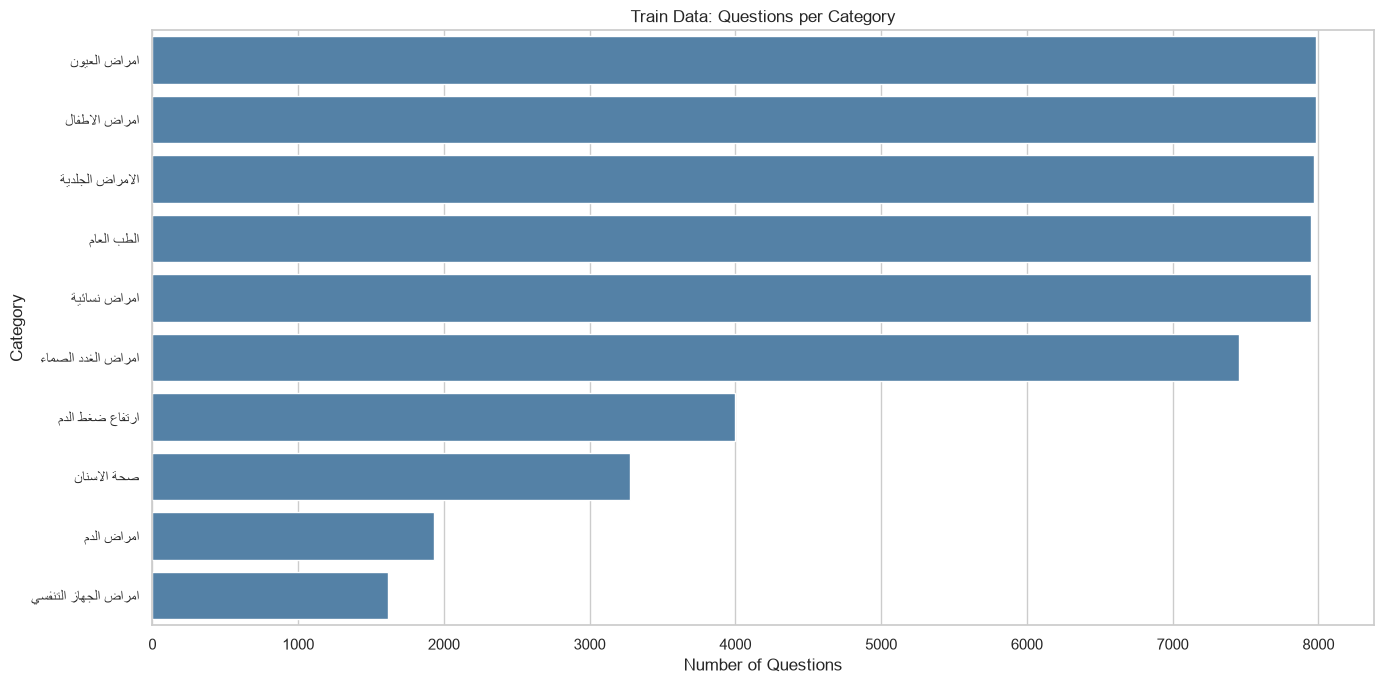

Largest category:
امراض العيون 7982

Smallest category:
امراض الجهاز التنفسي 1615

Imbalance Ratio:
4.942414860681114
Majority Class: امراض العيون (7,982)
Minority Class: امراض الجهاز التنفسي (1,615)
Imbalance Ratio (IR): 4.94 : 1



,Ratio vs Smallest
category,
امراض العيون,4.94
امراض الاطفال,4.94
الامراض الجلدية,4.93
الطب العام,4.92
امراض نسائية,4.92
امراض الغدد الصماء,4.62
ارتفاع ضغط الدم,2.48
صحة الاسنان,2.03
امراض الدم,1.20


In [235]:
show_some_stats_about_df(train_df, 'Train')

Lets check Validation

,Count
category,
امراض الاطفال,999
امراض العيون,998
الامراض الجلدية,996
امراض نسائية,994
الطب العام,994
امراض الغدد الصماء,930
ارتفاع ضغط الدم,500
صحة الاسنان,409
امراض الدم,240


,Count,Percentage
category,,
امراض الاطفال,999,13.758435
امراض العيون,998,13.744663
الامراض الجلدية,996,13.717119
امراض نسائية,994,13.689574
الطب العام,994,13.689574
امراض الغدد الصماء,930,12.808153
ارتفاع ضغط الدم,500,6.886104
صحة الاسنان,409,5.632833
امراض الدم,240,3.305330


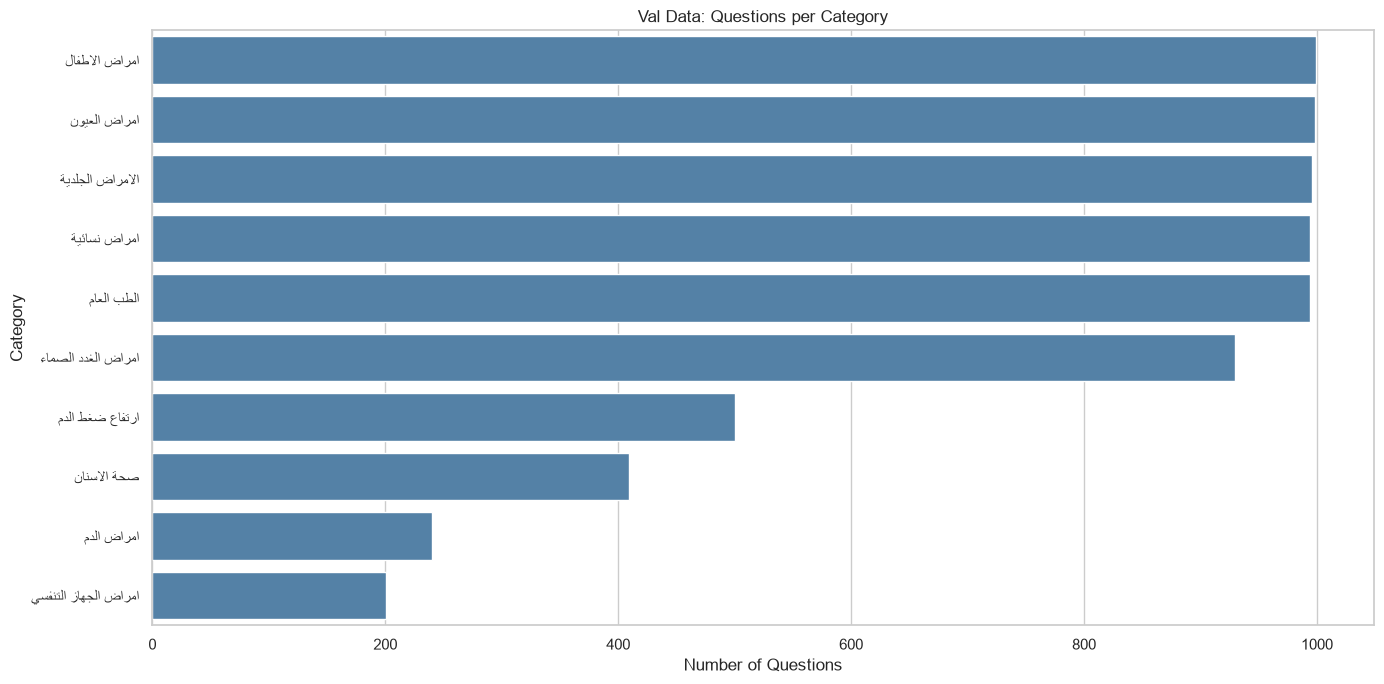

Largest category:
امراض الاطفال 999

Smallest category:
امراض الجهاز التنفسي 201

Imbalance Ratio:
4.970149253731344
Majority Class: امراض الاطفال (999)
Minority Class: امراض الجهاز التنفسي (201)
Imbalance Ratio (IR): 4.97 : 1



,Ratio vs Smallest
category,
امراض الاطفال,4.97
امراض العيون,4.97
الامراض الجلدية,4.96
امراض نسائية,4.95
الطب العام,4.95
امراض الغدد الصماء,4.63
ارتفاع ضغط الدم,2.49
صحة الاسنان,2.03
امراض الدم,1.19


In [236]:
show_some_stats_about_df(val_df,"Val")

seems they have same distrubtion, lets check

=== Summary Metrics ===
Train Total: 58,104 | Overall IR: 4.94 : 1
Val Total:   7,261 | Overall IR: 4.97 : 1



,Train Count,Val Count,Train %,Val %,Diff % (Train - Val),Train IR,Val IR
category,,,,,,,
ارتفاع ضغط الدم,3998,500,6.88,6.89,-0.01,2.48,2.49
الامراض الجلدية,7968,996,13.71,13.72,-0.01,4.93,4.96
الطب العام,7947,994,13.68,13.69,-0.01,4.92,4.95
امراض الاطفال,7980,999,13.73,13.76,-0.03,4.94,4.97
امراض الجهاز التنفسي,1615,201,2.78,2.77,0.01,1.00,1.00
امراض الدم,1932,240,3.33,3.31,0.02,1.20,1.19
امراض العيون,7982,998,13.74,13.74,0.00,4.94,4.97
امراض الغدد الصماء,7458,930,12.84,12.81,0.03,4.62,4.63
امراض نسائية,7947,994,13.68,13.69,-0.01,4.92,4.95


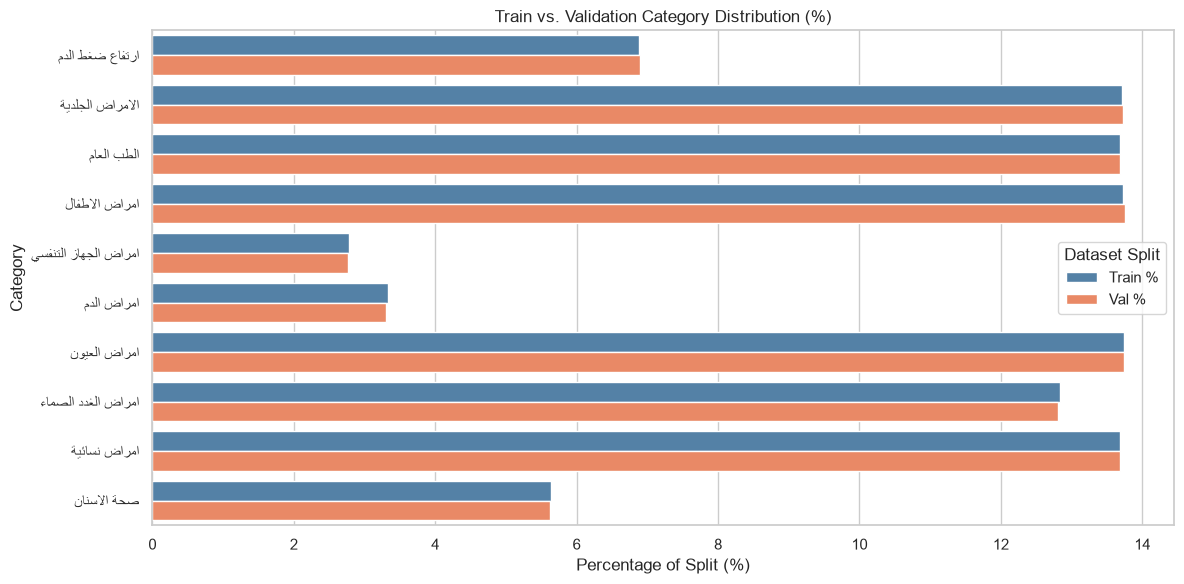

In [237]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def fix_arabic(text):
    return str(text)

def compare_train_val(train_df, val_df):
    # 1. Compute counts & percentages (fixing len(df) instead of len(train_df))
    train_counts = train_df["category"].value_counts()
    val_counts = val_df["category"].value_counts()
    
    comp_df = pd.DataFrame({
        "Train Count": train_counts,
        "Val Count": val_counts,
        "Train %": (train_counts / len(train_df) * 100).round(2),
        "Val %": (val_counts / len(val_df) * 100).round(2),
    })
    
    # Add difference column to verify stratification (should be close to 0.00%)
    comp_df["Diff % (Train - Val)"] = (comp_df["Train %"] - comp_df["Val %"]).round(2)
    
    # Add Ratio vs Smallest for both splits
    comp_df["Train IR"] = (train_counts / train_counts.min()).round(2)
    comp_df["Val IR"] = (val_counts / val_counts.min()).round(2)
    
    print("=== Summary Metrics ===")
    print(f"Train Total: {len(train_df):,} | Overall IR: {train_counts.max() / train_counts.min():.2f} : 1")
    print(f"Val Total:   {len(val_df):,} | Overall IR: {val_counts.max() / val_counts.min():.2f} : 1\n")
    
    display(comp_df)

    # 2. Side-by-Side Percentage Plot (Normalized so different split sizes compare fairly)
    plot_df = comp_df[["Train %", "Val %"]].reset_index().melt(
        id_vars="category", var_name="Split", value_name="Percentage"
    )
    
    plot_df["category_ar"] = plot_df["category"]

    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=plot_df,
        x="Percentage",
        y="category_ar",
        hue="Split",
        palette=["steelblue", "coral"]
    )
    plt.title("Train vs. Validation Category Distribution (%)")
    plt.xlabel("Percentage of Split (%)")
    plt.ylabel("Category")
    plt.legend(title="Dataset Split")
    plt.tight_layout()
    plt.show()

# Run the comparison
compare_train_val(train_df, val_df)


In [238]:
train_categories = set(train_df["category"].dropna().unique())
val_categories = set(val_df["category"].dropna().unique())

print("Categories in training:", len(train_categories))
print("Categories in validation:", len(val_categories))

print("\nCategories only in training:")
print(train_categories - val_categories)

print("\nCategories only in validation:")
print(val_categories - train_categories)

Categories in training: 10
Categories in validation: 10

Categories only in training:
set()

Categories only in validation:
set()


In [239]:
train_questions = set(train_df["question"].dropna())
val_questions = set(val_df["question"].dropna())
test_questions = set(test_df["question"].dropna())

print("Train-Validation question overlap:",
      len(train_questions & val_questions))

print("Train-Test question overlap:",
      len(train_questions & test_questions))

print("Validation-Test question overlap:",
      len(val_questions & test_questions))

Train-Validation question overlap: 0
Train-Test question overlap: 3
Validation-Test question overlap: 0


### Observations 2 & Summary of what i did

- cleaned categories from train and val sets, they have lables containing 'أ' instaed of 'ا'
- after cleaning made sure that our duplicated questions did not change
- saw each split distrubtion, the samples are biased, top 6 categoies has around twice the 7th category, and around 5 times more than smallest category
- train and val splits have the same distribution
- no missing categories from each split
- we already know 3 questions from test set, but it wont affect the result that much so i will keep them


<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Count</th>
      <th>Percentage</th>
    </tr>
    <tr>
      <th>category</th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>امراض العيون</th>
      <td>7988</td>
      <td>13.740432</td>
    </tr>
    <tr>
      <th>امراض الاطفال</th>
      <td>7986</td>
      <td>13.736991</td>
    </tr>
    <tr>
      <th>الامراض الجلدية</th>
      <td>7971</td>
      <td>13.711189</td>
    </tr>
    <tr>
      <th>الطب العام</th>
      <td>7954</td>
      <td>13.681947</td>
    </tr>
    <tr>
      <th>امراض نسائية</th>
      <td>7948</td>
      <td>13.671626</td>
    </tr>
    <tr>
      <th>امراض الغدد الصماء</th>
      <td>7462</td>
      <td>12.835641</td>
    </tr>
    <tr>
      <th>ارتفاع ضغط الدم</th>
      <td>3999</td>
      <td>6.878817</td>
    </tr>
    <tr>
      <th>صحة الاسنان</th>
      <td>3277</td>
      <td>5.636880</td>
    </tr>
    <tr>
      <th>امراض الدم</th>
      <td>1933</td>
      <td>3.325019</td>
    </tr>
    <tr>
      <th>امراض الجهاز التنفسي</th>
      <td>1617</td>
      <td>2.781457</td>
    </tr>
  </tbody>
</table>
</div>

## Text Understanding & Cleaning

In [240]:
import re


ENGLISH_PATTERN = re.compile(r'[a-zA-Z]')
ARABIC_DIGITS_PATTERN = re.compile(r'[٠-٩]')
ENGLISH_DIGITS_PATTERN = re.compile(r'[0-9]')
DIACRITICS_PATTERN = re.compile(r'[\u064B-\u065F\u0670]')
URL_PATTERN = re.compile(r'https?://\S+|www\.\S+')
EMAIL_PATTERN = re.compile(r'\S+@\S+\.\S+')

def analyze_text_features(text):

    text = str(text)

    return {
        
        "Has English": bool(ENGLISH_PATTERN.search(text)),
        "Has Arabic Digits": bool(ARABIC_DIGITS_PATTERN.search(text)),
        "Has English Digits": bool(ENGLISH_DIGITS_PATTERN.search(text)),
        "Has Diacritics": bool(DIACRITICS_PATTERN.search(text)),
        "Has URL": bool(URL_PATTERN.search(text)),
        "Has Email": bool(EMAIL_PATTERN.search(text)),
        "Has Newlines": "\n" in text or "\r" in text,
        "Has Punctuation": bool(re.search(r'[^\w\s]', text))
    }
    
text_features = pd.DataFrame(
    train_df["question"].apply(analyze_text_features).tolist()
)

feature_summary = pd.DataFrame({
    "Count": text_features.sum(),
    "Percentage": text_features.mean() * 100
})

display(feature_summary.sort_values("Count", ascending=False))

,Count,Percentage
Has Punctuation,31967,55.016866
Has English Digits,17074,29.385240
Has Newlines,9176,15.792372
Has Arabic Digits,8899,15.315641
Has English,6325,10.885653
Has Diacritics,4456,7.669007
Has URL,7,0.012047
Has Email,0,0.000000


In [241]:
def show_examples(df, pattern, n=5):

    mask = df["question"].str.contains(
        pattern,
        regex=True,
        na=False
    )

    display(df.loc[mask, ["question", "category"]].head(n))


In [242]:
# English terms
show_examples(train_df, r'[a-zA-Z]')


,question,category
3,انا فتاه غير متزوجة عمري 34 سنه وزني 75 سنه وطولي 160 اعاني من مشكلة الحديد . حيث دائما اراجع دكتور الغدة ودائما وفي كل فحص (خمس اشهر) يطلب مني دائما فحص الحديد وفي كل مره يكون سلبي ويكتب لي حبوب . وفي كل يزيد الجرعة اخر مره الحديد وصل الى ferritin - 19.3 ug/L بالرغم من انني شهر من علاجي للحديد وباقي شهر حيث اعطاني الدكتور فيروفيتا ما سبب نقص الحديد عندي رغم ان اكلي عادي واحب الكبدة لكن لا ا...,امراض الدم
8,نتائج التحليل tsh 6 ونسبة المختبر 0.25_5 /// 1.7 t3 ونسبة المختبر 0.9_2.3 //// t4 115 ونسبة المختبر 60_120 فهل هذاطبيعي علما لدي توقف دورة وتكيس منذ البلوغ ومتزوجة ماذا افعل,امراض الغدد الصماء
14,انقطاع الدورة الشهرية لمدة 4 أشهر كاملة، بعد ذلك، بدأ نزيف يومي مستمر، مع إفرازات بنية اللون، وأحياناً دم أسود أو أحمر. واستمرت ٣ اشهر اضافيه ،ارتفاعCRP1/96، حمى الحوض.,امراض نسائية
43,هل تؤثر تناول حبوب البرايورين للشعر (priorin) ع الليزر ؟!,الامراض الجلدية
57,لدي الم في الخصية احيانا\r\nعملت فحص طلع كلو تمام\r\nعملت تحليل هرمونات لكن لم افهم ما اذا كان لدي مشكلة في الهرمونات \r\nارجو تغسير التحليل \r\nلاني لاحظت انخفاض في مستوى هرمون FSH\r\nشكرا جزيلا,امراض الغدد الصماء


In [243]:
# Arabic digits
show_examples(train_df, r'[٠-٩]')


,question,category
0,العمر ٤٢ سنة مريض ضغط باخد بيزوكارد10 اشعر بإرهاق عام دائما فذهبت لعمل تحليل سكر تراكمي فهل انا اعاني من السكري من فضلك دكتور وما نصائحك في الحياة اليومية والغذاء والعلاج,امراض الغدد الصماء
11,هل يوجد دواء او هرمون يساعد في نمو عظام الوجه او الملامح علما اني بعمر ال٢٤ وشكلي كأني ١٤ سنه كذلك الفك السفلي صغير،هل اخذ هرمون النمو بعمر ال٢٤ يزيد عظام الوجه لو بشكل عرضي؟,امراض الغدد الصماء
12,نسبة فيتامين د عندي ٥٣.٣ هل يجب على تناول دواء ام يرتفع بتناول الاكل الصحي اعاني من تساقط الشعر و الام الركب تنمل الارجل و الخمول احيانًا,الطب العام
14,انقطاع الدورة الشهرية لمدة 4 أشهر كاملة، بعد ذلك، بدأ نزيف يومي مستمر، مع إفرازات بنية اللون، وأحياناً دم أسود أو أحمر. واستمرت ٣ اشهر اضافيه ،ارتفاعCRP1/96، حمى الحوض.,امراض نسائية
25,تحاليلي سليمة ولله الحمد و اشعة الصدر سليمة و نسبة الاكسجين ٩٨ و القلب سليم,امراض الجهاز التنفسي


In [244]:
# English digits
show_examples(train_df, r'[0-9]')


,question,category
0,العمر ٤٢ سنة مريض ضغط باخد بيزوكارد10 اشعر بإرهاق عام دائما فذهبت لعمل تحليل سكر تراكمي فهل انا اعاني من السكري من فضلك دكتور وما نصائحك في الحياة اليومية والغذاء والعلاج,امراض الغدد الصماء
3,انا فتاه غير متزوجة عمري 34 سنه وزني 75 سنه وطولي 160 اعاني من مشكلة الحديد . حيث دائما اراجع دكتور الغدة ودائما وفي كل فحص (خمس اشهر) يطلب مني دائما فحص الحديد وفي كل مره يكون سلبي ويكتب لي حبوب . وفي كل يزيد الجرعة اخر مره الحديد وصل الى ferritin - 19.3 ug/L بالرغم من انني شهر من علاجي للحديد وباقي شهر حيث اعطاني الدكتور فيروفيتا ما سبب نقص الحديد عندي رغم ان اكلي عادي واحب الكبدة لكن لا ا...,امراض الدم
4,تاخرت الدورة 14 يوم وعملت اختبار دم اليوم طلع حمل ضعيف وفي ميعاد الدورة نزل افرازات بنية هل هذا حمل,امراض نسائية
5,عمري 35سنة عزباء اريد تربية رضيع وارضعه رضاعة مستحثة كي يصبح ابنا لي كيف يمكن ذالك وماهي الادوية التي يمكن اخذها لرفع هرمون الحليب وماهي المدة اللازمة لتناولها لإدرار الحليب,امراض نسائية
8,نتائج التحليل tsh 6 ونسبة المختبر 0.25_5 /// 1.7 t3 ونسبة المختبر 0.9_2.3 //// t4 115 ونسبة المختبر 60_120 فهل هذاطبيعي علما لدي توقف دورة وتكيس منذ البلوغ ومتزوجة ماذا افعل,امراض الغدد الصماء


In [245]:



# URLs
show_examples(train_df, r'https?://|www\.', 10)

# Diacritics
show_examples(train_df, r'[\u064B-\u065F\u0670]')

,question,category
1749,السلام عليكم \r\nانا شاب عمري 17 عاما واعاني من مشكلة خروج الدم من الفرج كما الموضحة بالصورة في الرابط:\r\n\r\nhttp://colorectalsurgeonssydney.com.au/wp-content/uploads/2012/02/pilonidal-sinus.jpg\r\n\r\nالمشكلة ان الدم يخرج من هذا المنطقة كلما جلست او قمت بكمية صغيرة منذ 3 اسابيع\r\nوحاولت ان اجد حلا عبر وضع القليل من الملح ليتخثر الدم لكن لا فائدة\r\nوالان اعاني ببعض الالام كلما اقوم او اجلس...,امراض الدم
8277,جماعة انا عايز اشوف اذا كان فتحة الشرج عاندى طبيعية ولا لا وانا جبت صورتها http://alfaris.net/up/89/alfaris_net_1378738656.jpg,ارتفاع ضغط الدم
10347,هل عندما تسقط اللثة عن الاسنان ب 6 ملم هل هناك طريقة لاعادة اللثة ؟و هذه الصورة مرفقة و شكرا مسبقا\r\nhttp://www.mediafire.com/?d1l3mdbim7heut6,صحة الاسنان
25100,هل ممكن لعلاج سوبر قروث ان يزيد طولي بعد عمر 19\r\nhttp://www.growtallersupplements.net/arabic_growtaller_info.html,امراض الغدد الصماء
28025,https://altibbi.com/question/10755السلام عليكم \r\nاولا شكر كم على هذا الموقع الطبي الرائع من فترة ليس قريبة ظهرعلى الضرس خراج وماكنت اشعر بالم منه ... وبديت اشعر بالم تقريبا منذ اسبوع واخذت علاج ابر امبكلوكس تقريبا عشرة ابر بعدين راجعت طبيب وقام بقلع الضرس واعطني ابر كلافورام عدد 4 وحب مسكن وحب فلاجين .. وبعد يومين اكتشفت انه توجد بعض اجزاء من الضرس ... سؤالي هو اذا بقت هذه الاجزاء هل تسبب...,صحة الاسنان
37622,مشكله تضخم الثدى للرجال (gynecomastia)\r\nhttps://dvd4arab.maktoob.com/f99/4246253.html\r\nالسن / 22 سنه\r\nالطول / 172\r\nالوزن / كان 85 اصبح الان 73\r\nانا اعانى من مشكله تضخم الصدر بشكل ملحوظ و هى مشكله محرجه طبعا \r\nhttp://im45.gulfup.com/Qo9vli.jpg,امراض الغدد الصماء
48147,عملت تحاليل لدم وظهرت النتيجة كالاتي ارجو الايضاح في الصورتين ﺍﻟﺭﻭﺍﺑﻂ\nhttp://im56.gulfup.com/ZioGFz.jpg\nhttp://im56.gulfup.com/WO4Nk4.jpg,امراض الدم


,question,category
2,منذ حوالي خمسة أشهر، لاحظت نزول دم مع البراز لمدة أسبوع تقريبًا، ولم يكن مصحوبًا بأي ألم. أجريت منظارًا للقولون، وكانت النتيجة طبيعية. بالإضافة إلى ذلك، تظهر لدي أحيانًا نقاط حمراء صغيرة تحت الجلد، وأعاني من عدم انتظام الدورة الشهرية، حيث تأتي مرتين في بعض الأشهر. ما هي الأسباب المحتملة لهذه الأعراض المتنوعة، وما هي الفحوصات التي تنصحون بإجرائها؟,الطب العام
12,نسبة فيتامين د عندي ٥٣.٣ هل يجب على تناول دواء ام يرتفع بتناول الاكل الصحي اعاني من تساقط الشعر و الام الركب تنمل الارجل و الخمول احيانًا,الطب العام
14,انقطاع الدورة الشهرية لمدة 4 أشهر كاملة، بعد ذلك، بدأ نزيف يومي مستمر، مع إفرازات بنية اللون، وأحياناً دم أسود أو أحمر. واستمرت ٣ اشهر اضافيه ،ارتفاعCRP1/96، حمى الحوض.,امراض نسائية
27,أنا شاب عمري 29 سنة ولا أعاني من أية أمراض ولله الحمد سوى أن تم تشخيصي سابقاً بدوالي الخصية ولم أجري أي عملية جراحية إلى الأن لعلاجها، منذ شهرين أصبحت أمارس رياضة كمال الأجسام ومن أسبوعين قمت بفحص معدل التستوستيرون فتفاجئت بنسبة التستوستيرون الحر بأنها قليلة رغم ان المخبر يصنفها أنها طبيعية!,امراض الغدد الصماء
50,لدي افرازات مهبلية اقرب لرائحة البصل مع العلم انني لا اكثر من اكل البصل، مع ألم وحرقان اثناء الجماع\r\nعلمًا انني قبل اسبوعين تناولت علاج التهاب البول.,امراض نسائية


#### Cleaning Notes

- Since our task is classifying to medical category - no emotions - we can remove punctuations, newlines, diacritics, urls.

- english words are either a medicine name,  something related blood analysis/test, medical term, measurment units like (ml, mg ...)

- i would make arabic letters english or vice versa - since there is no differnce in meaning - most of them are used for age

- URLS are image links

- normalizing alef maybe useful - we should try

- we should try stemming also

In [246]:
def clean_whitespace(text):

    text = str(text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()
  
def remove_diacritics(text):

    return re.sub(
        r'[\u064B-\u065F\u0670]',
        '',
        text
    )
    
def normalize_alef(text):

    return re.sub(r'[أإآٱ]', 'ا', text)    
  
  
def remove_punctuation(text):

    return re.sub(r'[^\w\s]', ' ', text)  
  
ARABIC_TO_ENGLISH_DIGITS = str.maketrans("٠١٢٣٤٥٦٧٨٩", "0123456789")

def convert_arabic_digits(text):
    return text.translate(ARABIC_TO_ENGLISH_DIGITS)

def preprocessing(text):
    text = clean_whitespace(text)
    text = convert_arabic_digits(text)
    text = remove_diacritics(text)
    text = normalize_alef(text)
    # text = normalize_ya(text)
    text = remove_punctuation(text)

    return clean_whitespace(text)  

In [247]:
train_df_pre = train_df.copy()
train_df_pre["question"] = train_df_pre["question"].apply(
    preprocessing
)
val_df_pre = val_df.copy()
val_df_pre["question"] = val_df_pre["question"].apply(
    preprocessing
)


lets recheck what we checked in our dataset 

In [248]:
check_duplicated_conflict_categories(train_df , val_df)


(0, 4)


,split,id,question,category


In [249]:
check_duplicated_conflict_categories(train_df_pre , val_df_pre)

(4, 4)


,split,id,question,category
37893,Train,32344,عندي بردودة وتعرق في اليدين ولما عملت تحاليل قلولي عندك فرط في نشاط الغدة الدرقية كيف بقدر اقلل من نشاطها الزائد وايش الاشياء الي لو سويتها ممكن تتحكم بكمية افراز العرق,الامراض الجلدية
47681,Train,7245,عندي بردودة وتعرق في اليدين ولما عملت تحاليل قلولي عندك فرط في نشاط الغدة الدرقية كيف بقدر اقلل من نشاطها الزائد وايش الاشياء الي لو سويتها ممكن تتحكم بكمية افراز العرق,امراض الغدد الصماء
14332,Train,6739,نسبة الانسولين صائم 13 2 وتحليل السكر صائم 95 هل هذه القيم طبيعية وكيف احتسب مقاومة الانسولين من هذه النتائج هل انا مريض مقاومة انسولين مع العلم ان المعمل احتسب نسبة مقاومة الانسولين 1 7 اريد التاكد,امراض الغدد الصماء
64279,Val,43320,نسبة الانسولين صائم 13 2 وتحليل السكر صائم 95 هل هذه القيم طبيعية وكيف احتسب مقاومة الانسولين من هذه النتائج هل انا مريض مقاومة انسولين مع العلم ان المعمل احتسب نسبة مقاومة الانسولين 1 7 اريد التاكد,الطب العام


In [250]:
check_duplicates(train_df, val_df)
        
print("\nAfter Processing : ")
check_duplicates(train_df_pre, val_df_pre)
check_empty(train_df_pre, val_df_pre)
train_df = train_df_pre
val_df = val_df_pre


Train: 0 duplicate questions
With Category: 0 duplicate questions
Validation: 0 duplicate questions
With Category: 0 duplicate questions
Train-val: 0 duplicate questions
With Category: 0 duplicate questions

After Processing : 
Train: 6 duplicate questions
With Category: 5 duplicate questions
Validation: 0 duplicate questions
With Category: 0 duplicate questions
Train-val: 9 duplicate questions
With Category: 7 duplicate questions
Train: 0 empty questions
Validation: 0 empty questions


In [287]:
train_df , val_df = clean_duplicates(train_df_pre , val_df_pre)

Train duplicates left:     0
Val duplicates left:       0
Train-Val overlap left:    0


In [288]:
train_df["question_length"] = (
    train_df["question"]
    .fillna("")
    .str.len()
)

train_df["word_count"] = (
    train_df["question"]
    .fillna("")
    .str.split()
    .str.len()
)

In [289]:
display(
    train_df[["question_length", "word_count"]]
    .describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
)

,count,mean,std,min,5%,25%,50%,75%,95%,max
question_length,58096.0,138.252702,71.443679,7.0,38.0,85.0,134.0,172.0,285.0,881.0
word_count,58096.0,26.808438,13.886251,1.0,7.0,16.0,26.0,34.0,54.0,166.0


There is some questions with one word, should be handled.


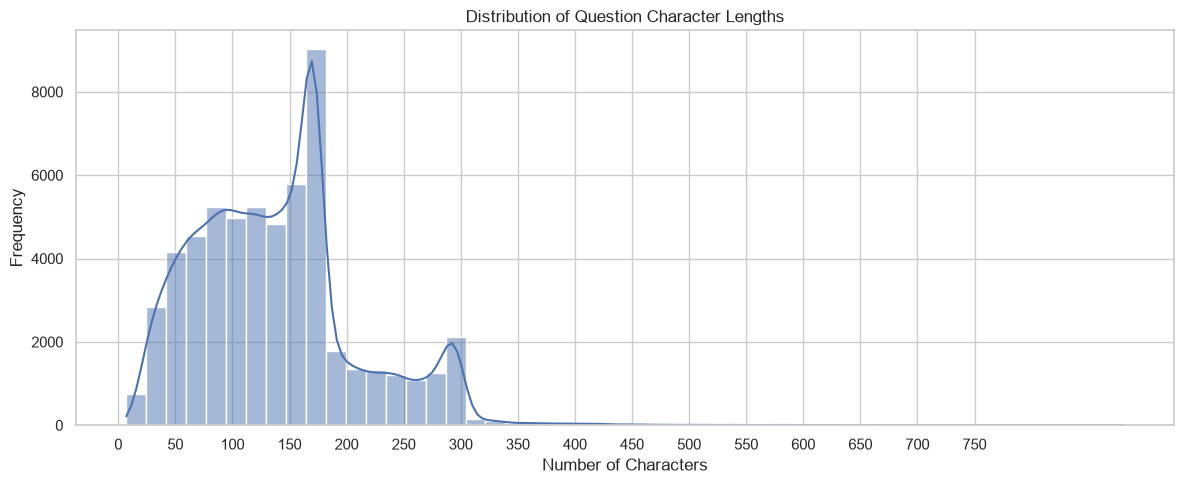

In [290]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=train_df,
    x="question_length",
    bins=50,
    kde=True
)

x_ticks = [i for i in range(0, 800 , 50)]
plt.xticks(x_ticks)
plt.title("Distribution of Question Character Lengths")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

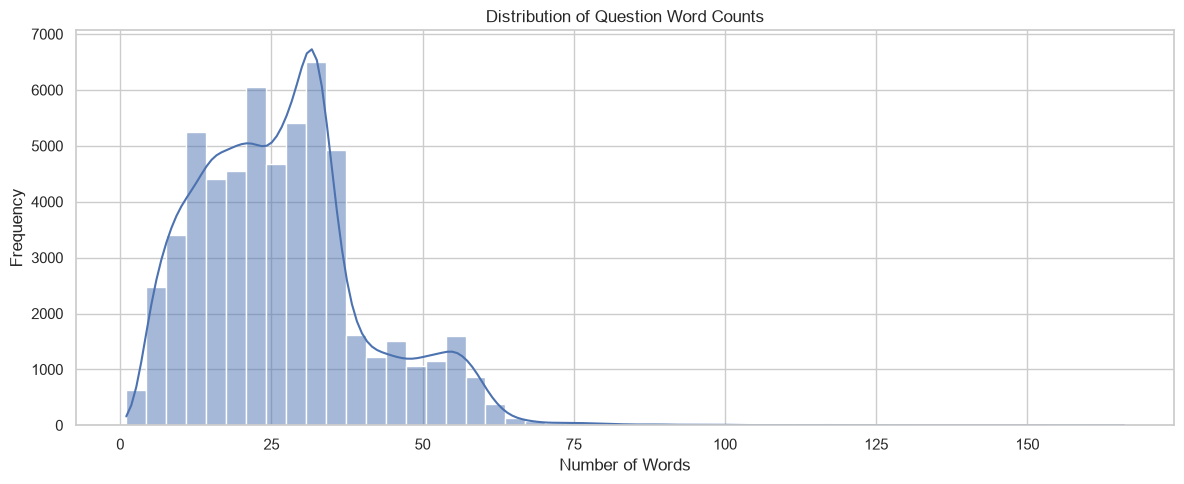

In [255]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=train_df,
    x="word_count",
    bins=50,
    kde=True
)

plt.title("Distribution of Question Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [291]:
print("Shortest questions:")
display(
    train_df.nsmallest(20, "question_length")[
        ["question", "category", "question_length","word_count"]
    ]
)

print("Longest questions:")
display(
    train_df.nlargest(5, "question_length")[
        ["question", "category", "question_length", 'word_count']
    ]
)

Shortest questions:


,question,category,question_length,word_count
45251,استفسار,امراض الغدد الصماء,7,1
41310,ضغط الدم,ارتفاع ضغط الدم,8,2
14872,ضغط العين,امراض العيون,9,2
28701,hemopilia,امراض الدم,9,1
35394,ظفر العين,امراض العيون,9,2
45691,ضرس منخور,صحة الاسنان,9,2
1617,نزلة معوية,امراض الجهاز التنفسي,10,2
38383,الام الضرس,صحة الاسنان,10,2
14000,علاج التسوس,صحة الاسنان,11,2
22094,امراض نفسيه,ارتفاع ضغط الدم,11,2


Longest questions:


,question,category,question_length,word_count
18816,السلام عليكم انا عندي 21 سنه وانثي وكنت اعاني من صداع وطنين وعرفت ان ضروس العقل الاربعه عندي مدفونين وقمت بعمل عمليه وخلع ضرس السفلي واخذت حقنتين يوناسين ولم اتحملها ف اكملت ب اوجمانتين اقراص واخد مسكنات كثيره مثل فولتارين وبروفين وكيتوفان ومن بعد العمليه باسبوع بدات اشعر بدوخه وخمول ونقط تلمع كثيره وصغيره جدا امام عيني تظهر في الظلام او علي سطح فاتح ف ذهبت لدكتور عيون فحص عيني والشبكيه وضغط العين والقاع وقال اني عيني سليمه تماما ثم ذهبت الي انف واذن وعمل لي اشاعه توازن كامله واشاعه علي المخ ووجد ان اذني والمخ سليم ولا يوجد اي مشكله واعطاني لوسيدريل ذهبت الدوخه الي حد ما ولكن بقت عيني بهذه النقط ورغبه دائمه بالنعاس والنوم وقومت بقياس ضغط وسكر وتحليل دم وكله سليم ماذا عن النقط وهل يمكن ان تكون بسبب العمليه اوبسبب اني مشلتش باقي ضروس العقل المدفونه وهل يمكن ان تكون حاله نفسيه لاني امر ال...,صحة الاسنان,881,166
547,اشتكي من تقصف اضافري بحيث تظهر بشكل خطوط طوليه بشكل بارز ولو طال اظفاري شويتين انشق الاظفر اللي طال خارجا من احد التكسيرات الطوليه اتمنى وصل وقدرت افهمكم عمري 34 وطولي بينقص كل مره سانتي من 160 الى 158 الان ووزني 47 بعد ان كان مابين 50 و 49 بشكل ثابت سابقا باكل الخضراوات والبروتين والحليب بس طبيعتي مقله بالاكل بالعموم حركتي قليله لان شغلي غالبه على النت ايضا شعري اصبح خفيف ويتساقط وفروة راسي دهنيه وشعري جاب بشرتي جافه جدا رغم الترطيب المستمر وتتحسس وتبقع بلون وردي او احمر على العضد تظهر بقع حمرا زي الحساسيه وتخشن بعدين حساسيه في منطقه الخاصة التناسليه وقبل كم سنه حصلت لي خرجات داخليه بنفس المنطقه واخذت مضادات حيويه الى انفجارها واستمرت سنتين تظهر بشهر رجب وشوال على التوالي فقط وتعافيت منها الا ان شكل وحالتها تغيرت وصارت منطقه حساسه وتجف واحيان بعد الحلاقه تظهر حبوب بيضا اعتذر طولت عليك...,امراض الغدد الصماء,826,152
14968,السلام عليكم انا فتاة عمري 20 سنه مشكلتي ارتفاع ضغط العين ورحت للدكتور قبل سنتين تقريبا واعطاني قطرات كثيرة مثل ترافاتان وزالاتان وزولامول استعملها مرة واحدة قبل النوم وكنت اراجع العيادة باستمرار لحد مارجع ضغط عيني للطبيعي وقال لي الدكتور اني اوقف القطرات وتابعت قياس الضغط بعد شهر من التوقف عن استعمال القطرة وثبت الضغط طبيعي فطلب مني الدكتور فقط بقياس الضغط كل فترة للاطمئنان وكذلك عمل لي فحص فيجوال فيلد وقال ان العصب سليم وراجعت الان بعد مرور السنتين وطلب مني دكتور اخر للعيون عمل فيجوال فيلد مرة اخرة وقال لي ان العصب تالف بمقدار 50 بالميه مع ان قياس الضغط كان طبيعي فوصف لي قطرة ديوتراف استمر عليها طوال حياتي ليحافظ علة ماتبقى من العصب سؤالي كيف يتاثر للعصب اذا كان الضغط سليم ولماذ الطبيب الاول طلب مني التوقف عن الدواء مع انه قد يتاثر العصب وهل اذا استعملت القطرة سيتاثر الباقي من العصب,ارتفاع ضغط الدم,795,146
31611,مشكلتي هي انني اصبت بوكعة صحية وذهبت الي المركز الطبي واعطوني مسكن عن طريق الوريد وقد تسبب لي بكارثة صحية كبيرة حيث اتضح ان هذا المسكن تسبب لي التهاب حاد في الكليتين وهذا ما يسمي ب اﻻلتهاب الكلوي الحاد مما ادي الي توقف وظيفة الكليتين تماما وارتفاع مضطرد في ضفط الدم كذلك ادي الي ارتفاع نسبة الكرياتنين الي 490 وخضعت تحت العﻻج والمراقبة لمدة عشرة ايام في المستشفي وقرر الدكتور في بداية اﻻمر ان ياخذ عينة من الكليتين بعد ان وجود الدكتور المختص بعدم جدوي العﻻج وبعد ذلك وبمشيئة الله عز وجل اخذت صحتي تتحسسن شيئا فشيئا حيث وصلت قرائة ضغطي اﻻن بمعدل 60 116 ونبطات قلبي ال60 70 الكراتنين وصل تقريبا الي المعدل الطبيعي وهو 70 سؤالي هو هل مثل حالتي سوف تكون قد تجاوزت الخطر وان هذه الحالة سوف لن تعود لي انشاء الله وبماذا تقترح ان اقوم بطبيقه في المستقبل ولكم جزيل الشكر والتفدير,ارتفاع ضغط الدم,771,147
10631,السلام عليكم انا شاب عمري 25 سنه تعرضت وانا صغير لحادثه ادت لظهور ندبة على الوجه قمت بالعديد من التجارب منها عملية لازالة الندب قبل 6 سنين ثم ليزر قبل 3 سنين وها انا بدات vbeam laser قبل 3 اشهر لازالة الاحمرار للاسف قام الطبيب باعطائي ثلالث ادوية كخليط منها protopic hydroqouinine and differine قامت بحساسية مفرطة لجلدي وقمت باستعمالهم لشهز كامل ولم اعلم انها حساسية كان الجرح يتضاعف احمراره ل 5 مرات اصبح هناك خط قرب الندبة لونه اسود بنفس حجم الجرح يبدو اني قد زدت الكميه لقد زاد الطين بله اادواء وجهي يادكتور اكثر من تشوهه لا اريد اي شيء غير ان يرحع جرحي مثل قبل 3 اشهر السواد دمرني ولا اعلم ما الحل ارجو ان تفيدني لان هذا الجرح قد دمر حياتي وقد ندمت جدا على ال

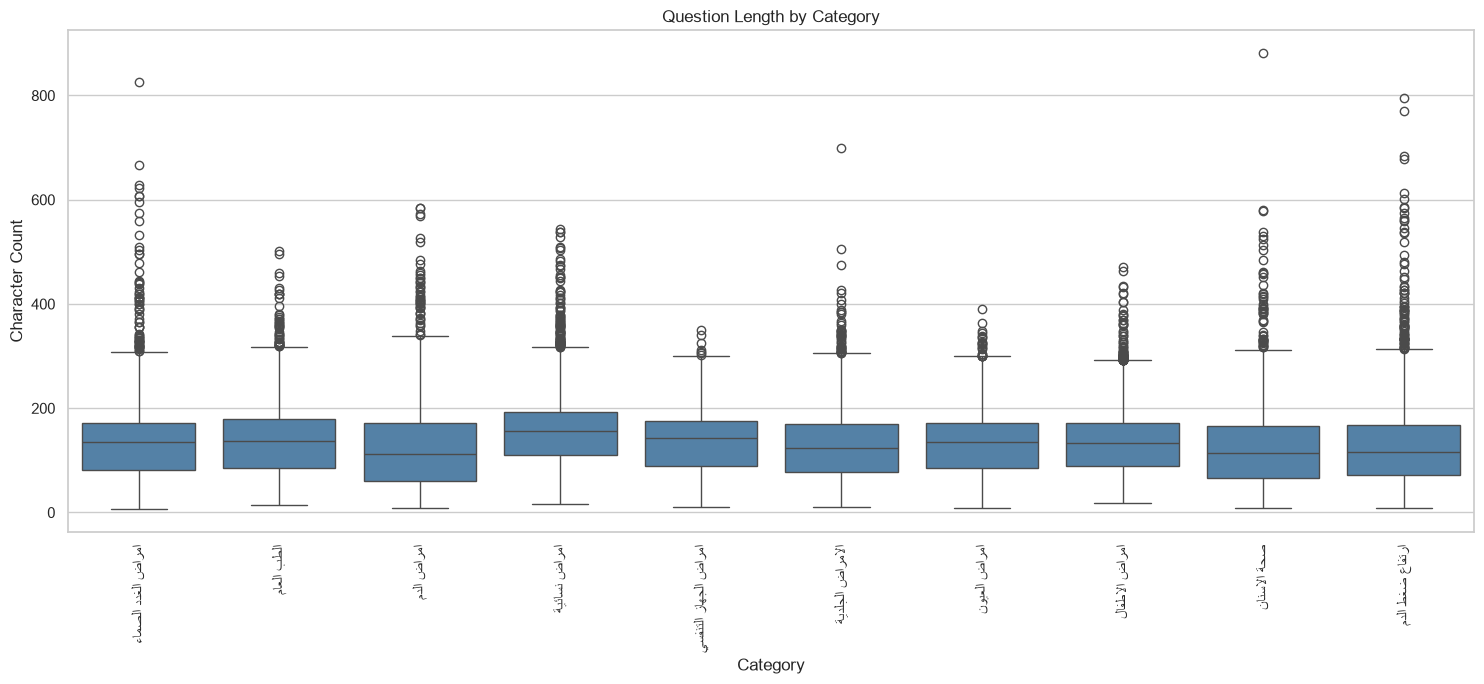

In [292]:
plt.figure(figsize=(15, 7))

sns.boxplot(
    data=train_df,
    x="category",
    y="question_length",
    color="steelblue"
)

plt.title("Question Length by Category")
plt.xlabel("Category")
plt.ylabel("Character Count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

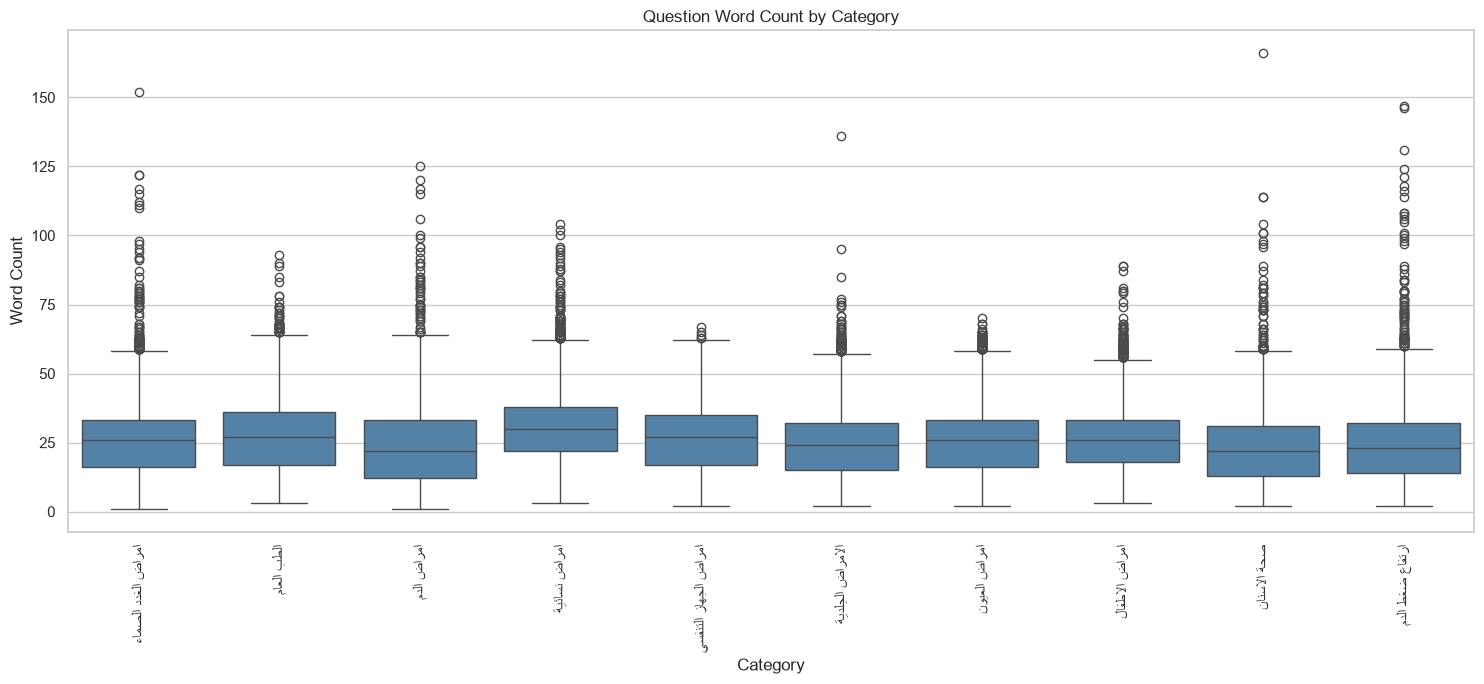

In [293]:
plt.figure(figsize=(15, 7))

sns.boxplot(
    data=train_df,
    x="category",
    y="word_count",
    color="steelblue"
)

plt.title("Question Word Count by Category")
plt.xlabel("Category")
plt.ylabel("Word Count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

#### Observations 3
- word count (mean : 26.823162	, std : 13) - most questions have 26 +-13 words
- most questions are under 70 words
- questions word counts across categories are fairly similiar - i think this is useful so model does not make an association between the question lenght and the label - maybe.




In [294]:
short_questions = train_df[
    train_df["word_count"] <= 3
].copy().sort_values("word_count")

print("Questions with 3 words or fewer:", len(short_questions))

display(
    short_questions[
        ["question", "category"]
    ].head(10)
)

Questions with 3 words or fewer: 179


,question,category
28701,hemopilia,امراض الدم
45251,استفسار,امراض الغدد الصماء
14872,ضغط العين,امراض العيون
1617,نزلة معوية,امراض الجهاز التنفسي
17467,الكرياتنين الطبيعي,صحة الاسنان
22094,امراض نفسيه,ارتفاع ضغط الدم
39549,تورم العيون,امراض العيون
5908,ماهوضغط الدم,ارتفاع ضغط الدم
35394,ظفر العين,امراض العيون
39909,اصفرار العين,امراض العيون


### Label mapping

In [262]:
display(label_mapping_df.head(20))

print("Mapping columns:", label_mapping_df.columns.tolist())
print("Mapping shape:", label_mapping_df.shape)

,category,label_id
0,امراض العيون,0
1,الامراض الجلدية,1
2,الطب العام,2
3,امراض نسائية,3
4,امراض الغدد الصماء,4
5,امراض الاطفال,5
6,ارتفاع ضغط الدم,6
7,صحة الاسنان,7
8,امراض الدم,8
9,امراض الجهاز التنفسي,9


Mapping columns: ['category', 'label_id']
Mapping shape: (10, 2)


In [263]:
LABEL_COL = "category"  
ID_COL = "label_id"     

print("Number of mapping entries:", len(label_mapping_df))

print("Duplicate category names:",
      label_mapping_df[LABEL_COL].duplicated().sum())

print("Duplicate label IDs:",
      label_mapping_df[ID_COL].duplicated().sum())

print("Categories missing from mapping:",
      train_categories - set(label_mapping_df[LABEL_COL]))

print("Extra categories in mapping:",
      set(label_mapping_df[LABEL_COL]) - train_categories)

Number of mapping entries: 10
Duplicate category names: 0
Duplicate label IDs: 0
Categories missing from mapping: set()
Extra categories in mapping: set()


### Sample verification

In [265]:
print("Submission columns:", sample_submission_df.columns.tolist())

print("Test IDs count:", len(test_df))
print("Submission IDs count:", len(sample_submission_df))

print(
    "IDs match:",
    test_df["id"].reset_index(drop=True).equals(
        sample_submission_df["id"].reset_index(drop=True)
    )
)

Submission columns: ['id', 'category']
Test IDs count: 7267
Submission IDs count: 7267
IDs match: True


# Baseline

In [297]:
from sklearn.feature_extraction.text import CountVectorizer

X_train = train_df["question"].copy()

X_val = val_df["question"].copy()

# Use the official label mapping
category_to_id = dict(
    zip(
        label_mapping_df["category"],
        label_mapping_df["label_id"]
    )
)

y_train = train_df["category"].map(category_to_id)
y_val = val_df["category"].map(category_to_id)

assert y_train.notna().all()
assert y_val.notna().all()

y_train = y_train.astype(int)
y_val = y_val.astype(int)


In [299]:
vectorizer = CountVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
)

X_train_vec = vectorizer.fit_transform(X_train)

X_val_vec = vectorizer.transform(X_val)

print("Training matrix:", X_train_vec.shape)
print("Validation matrix:", X_val_vec.shape)

Training matrix: (58096, 171076)
Validation matrix: (7258, 171076)


In [300]:
from sklearn.linear_model import LogisticRegression


clf = LogisticRegression()

clf.fit(X_train_vec, y_train)
score = clf.score(X_val_vec, y_val)

print("Accuracy:", score)


Accuracy: 0.8414163681454946


TODO: 
- Stopwords
- Stemming
- 

# Draft

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

In [ ]:
X_train = train_df["question"].copy()

X_val = val_df["question"].copy()

# Use the official label mapping
category_to_id = dict(
    zip(
        label_mapping_df["category"],
        label_mapping_df["label_id"]
    )
)

y_train = train_df["category"].map(category_to_id)
y_val = val_df["category"].map(category_to_id)

assert y_train.notna().all()
assert y_val.notna().all()

y_train = y_train.astype(int)
y_val = y_val.astype(int)

In [ ]:
tfidf = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    max_features=200_000
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_val_tfidf = tfidf.transform(X_val)

print("Training matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)

Training matrix: (58104, 171134)
Validation matrix: (7261, 171134)


In [ ]:
from sklearn.linear_model import LogisticRegression


model = LinearSVC(
    C=1.0,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

d:\Study\NLP\.venv12\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

In [270]:
y_pred = model.predict(X_val_tfidf)

In [271]:
accuracy = accuracy_score(y_val, y_pred)

macro_f1 = f1_score(
    y_val,
    y_pred,
    average="macro"
)

weighted_f1 = f1_score(
    y_val,
    y_pred,
    average="weighted"
)

print(f"Accuracy:    {accuracy:.4f}")
print(f"Macro F1:    {macro_f1:.4f}")
print(f"Weighted F1: {weighted_f1:.4f}")

Accuracy:    0.8398
Macro F1:    0.8112
Weighted F1: 0.8388


In [272]:
id_to_category = {
    label_id: category
    for category, label_id in category_to_id.items()
}

target_ids = sorted(id_to_category)

target_names = [
    id_to_category[label_id]
    for label_id in target_ids
]

print(
    classification_report(
        y_val,
        y_pred,
        labels=target_ids,
        target_names=target_names,
        digits=4,
        zero_division=0
    )
)

                      precision    recall  f1-score   support

        امراض العيون     0.9305    0.9128    0.9216       998
     الامراض الجلدية     0.8062    0.8936    0.8476       996
          الطب العام     0.6604    0.7475    0.7013       994
        امراض نسائية     0.9159    0.9205    0.9182       994
  امراض الغدد الصماء     0.8243    0.8022    0.8131       930
       امراض الاطفال     0.8823    0.9079    0.8949       999
     ارتفاع ضغط الدم     0.8584    0.7880    0.8217       500
         صحة الاسنان     0.9627    0.8826    0.9209       409
          امراض الدم     0.8000    0.4833    0.6026       240
امراض الجهاز التنفسي     0.8099    0.5721    0.6706       201

            accuracy                         0.8398      7261
           macro avg     0.8451    0.7911    0.8112      7261
        weighted avg     0.8434    0.8398    0.8388      7261



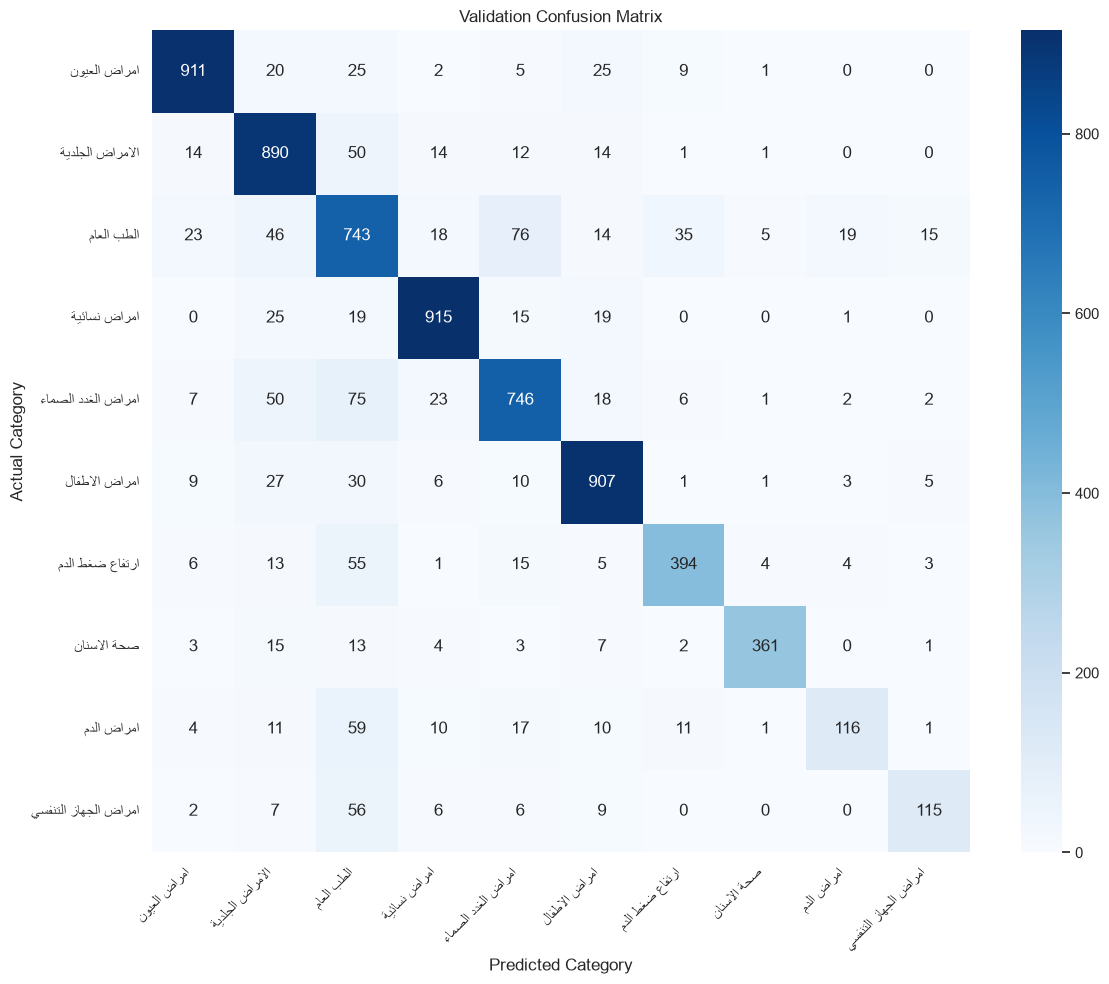

In [273]:
cm = confusion_matrix(
    y_val,
    y_pred,
    labels=target_ids
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names
)

plt.title("Validation Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

TODO : text understanding, statistics 
-	تحليل الأسئلة واستكشاف طبيعة النصوص والأنماط اللغوية الموجودة فيها.
-	البحث عن الأسئلة المتكررة أو المتشابهة.
-	فحص النصوص بحثاً عن المشكلات التي قد تؤثر في عملية التدريب.
-	التحقق من وجود ضوضاء في البيانات.
- Preprocessing from the docx
- label mapping
- building baseline

# Kaggle

In [274]:
X_test = test_df["question"].apply(
    normalized_preprocessing
)

X_test_tfidf = tfidf.transform(X_test)

test_predictions = model.predict(X_test_tfidf)
submission = sample_submission_df.copy()

submission["category"] = test_predictions

submission["category"] = submission["category"].astype(int)

assert submission["id"].equals(test_df["id"])
assert submission["category"].notna().all()

submission.to_csv("submission.csv", index=False)

display(submission.head())

print("Submission shape:", submission.shape)

,id,category
0,24452,1
1,10653,4
2,16110,3
3,40095,2
4,47029,5


Submission shape: (7267, 2)
